In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import find_peaks
from scipy.special import gammaln

np.random.seed(42)

url = "https://www.sidc.be/SILSO/INFO/snmtotcsv.php"
try:
    df = pd.read_csv(url, sep=";", header=None,
                     names=["year","month","date","sunspots","std","nobs","prov"])
except Exception as e:
    print("Download failed, upload Sunspots.csv instead:", e)
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

df = df[(df.year >= 1749) & ((df.year < 2018) | ((df.year == 2018) & (df.month <= 11)))]
df = df.reset_index(drop=True)
y = df["sunspots"].values.astype(float)
n = len(y)
print(n, "months")
df.head()

3239 months


,year,month,date,sunspots,std,nobs,prov
0,1749,1,1749.042,96.7,-1.0,-1,1
1,1749,2,1749.123,104.3,-1.0,-1,1
2,1749,3,1749.204,116.7,-1.0,-1,1
3,1749,4,1749.288,92.8,-1.0,-1,1
4,1749,5,1749.371,141.7,-1.0,-1,1


Step 1. Plot the data over the years to see what the distribution might be like

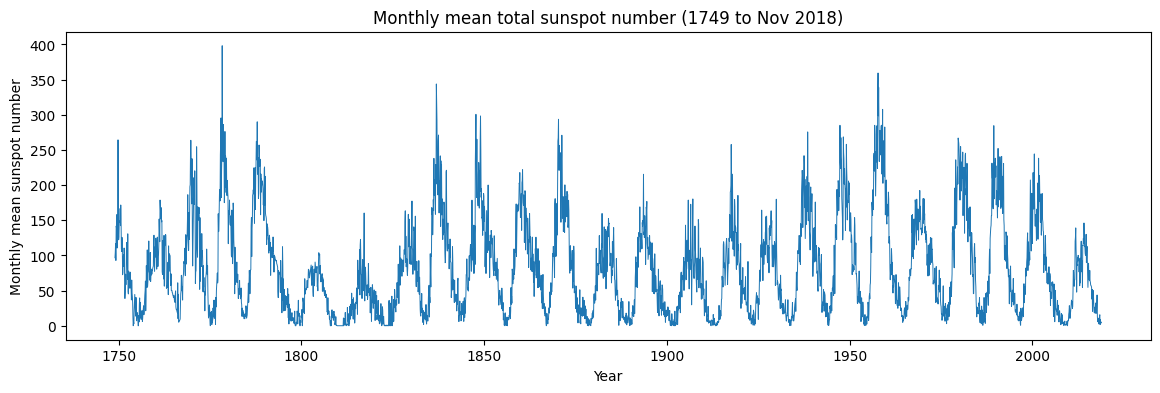

CONCLUSION (Step 1)
1. The series rises and falls repeatedly, with 25 clear cycle peaks found.
2. The average gap between peaks is about 11.0 years, close to the known 11-year solar cycle.
3. The highest monthly value is 398 in 1778.3, while the overall mean is only 82.4.
4. Peak heights differ a lot between cycles, so one fixed curve can only describe the average cycle.


In [6]:
t_years = df["year"] + (df["month"] - 1) / 12
plt.figure(figsize=(14,4))
plt.plot(t_years, y, lw=0.7)
plt.xlabel("Year"); plt.ylabel("Monthly mean sunspot number")
plt.title("Monthly mean total sunspot number (1749 to Nov 2018)")
plt.show()

smooth = pd.Series(y).rolling(13, center=True, min_periods=1).mean().values
pk_idx, _ = find_peaks(smooth, distance=72, prominence=20)
pk_years = t_years.values[pk_idx]
cycle_len = np.diff(pk_years).mean()
imax = np.argmax(y)

print("explaination")
print(f"1. The series rises and falls repeatedly, with {len(pk_idx)} clear cycle peaks found.")
print(f"2. The average gap between peaks is about {cycle_len:.1f} years, close to the known 11-year solar cycle.")
print(f"3. The highest monthly value is {y[imax]:.0f} in {t_years.values[imax]:.1f}, while the overall mean is only {y.mean():.1f}.")
print("4. Peak heights differ a lot between cycles, so one fixed curve can only describe the average cycle.")

Step 2. Model the phenomenon with a gamma distribution, with a new cycle resetting every 12 years

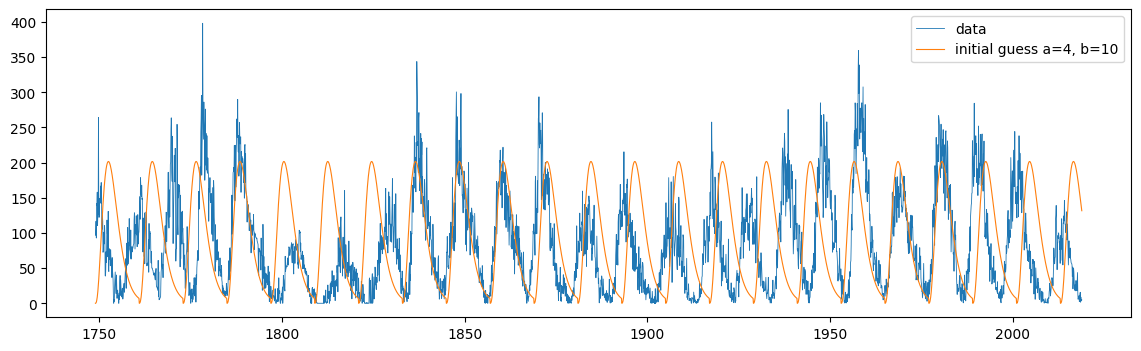

explnation
1. The guess a=4, b=10 puts the peak at phase 0.30, which is 3.6 years into each 12-year cycle.
2. The repeating curve has correlation 0.19 with the data and RMSE 87.6, so it is a rough but usable starting point.
3. Every cycle gets the same height, so the curve cannot match strong and weak cycles at the same time.
4. MCMC will tune a and b (and height S and noise sigma) to reduce this error.


In [7]:
CYCLE = 144
month_idx = np.arange(n)
u = ((month_idx % CYCLE) + 0.5) / CYCLE

def gamma_pdf(u, a, b):
    return np.exp(a*np.log(b) - gammaln(a) + (a-1)*np.log(u) - b*u)

def log_post(theta):
    a, b, S, sig = np.exp(theta)
    if not (0.5 < a < 30 and 0.5 < b < 100 and 1 < S < 1000 and 1 < sig < 200):
        return -np.inf
    mu = S * gamma_pdf(u, a, b)
    return -n*np.log(sig) - 0.5*np.sum((y - mu)**2) / sig**2

mu0 = 90 * gamma_pdf(u, 4, 10)
plt.figure(figsize=(14,4))
plt.plot(t_years, y, lw=0.6, label="data")
plt.plot(t_years, mu0, lw=0.8, label="initial guess a=4, b=10")
plt.legend(); plt.show()

corr0 = np.corrcoef(y, mu0)[0, 1]
rmse0 = np.sqrt(np.mean((y - mu0)**2))
print("explnation")
print(f"1. The guess a=4, b=10 puts the peak at phase {(4-1)/10:.2f}, which is {(4-1)/10*12:.1f} years into each 12-year cycle.")
print(f"2. The repeating curve has correlation {corr0:.2f} with the data and RMSE {rmse0:.1f}, so it is a rough but usable starting point.")
print("3. Every cycle gets the same height, so the curve cannot match strong and weak cycles at the same time.")
print("4. MCMC will tune a and b (and height S and noise sigma) to reduce this error.")

Step 3. Histogram of sunspot counts Step 4. a=4, and b =10 so plot MNMC for groups: First 50 samples, All samples, Last 50 samples

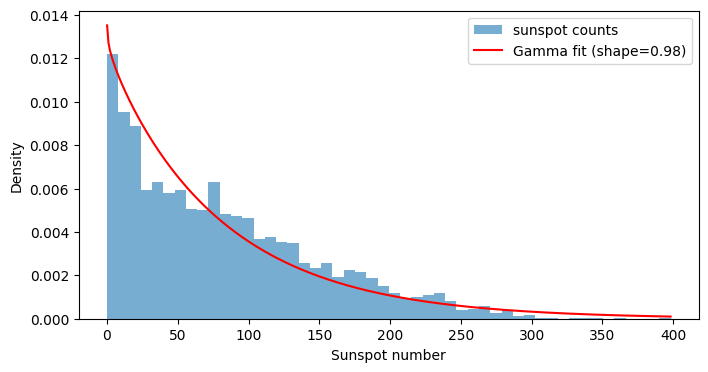

Explaination
1. The histogram is right-skewed (skewness = 0.92): most months have low counts and a few have very high ones.
2. The mean (82.4) is larger than the median (68.3), which confirms the long right tail.
3. A Gamma fit gives shape = 0.98 and scale = 84.2, and its curve follows the bars reasonably well.
4. Counts are never negative and are skewed, so a Gamma distribution is a sensible choice.


In [9]:
plt.figure(figsize=(8,4))
plt.hist(y, bins=50, density=True, alpha=0.6, label="sunspot counts")
yy = np.clip(y, 0.1, None)
sh, loc, sc = stats.gamma.fit(yy, floc=0)
xs = np.linspace(0.1, y.max(), 400)
plt.plot(xs, stats.gamma.pdf(xs, sh, loc, sc), "r", label=f"Gamma fit (shape={sh:.2f})")
plt.xlabel("Sunspot number"); plt.ylabel("Density"); plt.legend(); plt.show()

print("Explaination")
print(f"1. The histogram is right-skewed (skewness = {stats.skew(y):.2f}): most months have low counts and a few have very high ones.")
print(f"2. The mean ({y.mean():.1f}) is larger than the median ({np.median(y):.1f}), which confirms the long right tail.")
print(f"3. A Gamma fit gives shape = {sh:.2f} and scale = {sc:.1f}, and its curve follows the bars reasonably well.")
print("4. Counts are never negative and are skewed, so a Gamma distribution is a sensible choice.")

In [11]:
#Run MCMC
def metropolis(n_iter=30000, start=(4, 10, 50, 40), step=(0.05, 0.05, 0.03, 0.02)):
    theta = np.log(np.array(start, float))
    lp = log_post(theta)
    chain = np.zeros((n_iter, 4)); acc = 0
    step = np.array(step)
    for i in range(n_iter):
        prop = theta + np.random.normal(0, step)
        lp_prop = log_post(prop)
        if np.log(np.random.rand()) < lp_prop - lp:
            theta, lp = prop, lp_prop; acc += 1
        chain[i] = np.exp(theta)
    print(f"Acceptance rate: {acc/n_iter:.2%}")
    return chain

chain = metropolis()
a_tr, b_tr, S_tr, sig_tr = chain.T

Acceptance rate: 9.10%


plot MNMC for groups: First 50 samples, All samples, Last 50 samples

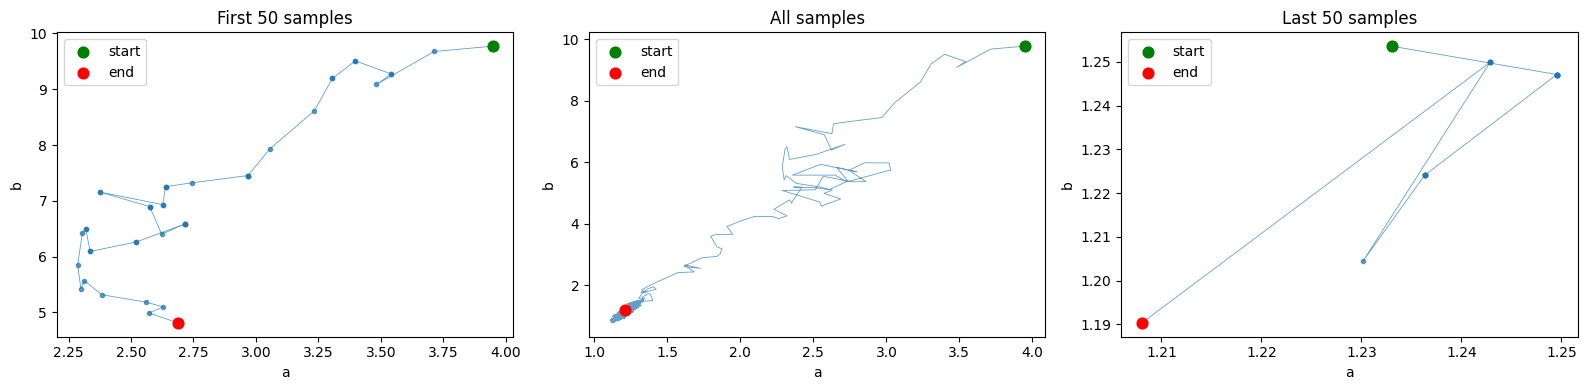

Explaination
1. In the first 50 samples the chain moves 5.12 units away from the start (a=4, b=10).
2. Over all samples it travels 9.01 units in total, ending near a = 1.21, b = 1.19.
3. In the last 50 samples the spread is small (std of a = 0.009, std of b = 0.016), so the chain has settled.
4. The correlation between a and b is 0.91, so the cloud stretches along a ridge and the two parameters work together.


In [13]:
groups = {"First 50 samples": slice(0,50),
          "All samples": slice(0,len(chain)),
          "Last 50 samples": slice(len(chain)-50, len(chain))}

fig, axs = plt.subplots(1, 3, figsize=(16,4))
for ax, (name, sl) in zip(axs, groups.items()):
    ax.plot(a_tr[sl], b_tr[sl], "-o" if name != "All samples" else "-",
            ms=3, lw=0.6, alpha=0.7)
    ax.scatter(a_tr[sl][0], b_tr[sl][0], c="g", s=60, zorder=5, label="start")
    ax.scatter(a_tr[sl][-1], b_tr[sl][-1], c="r", s=60, zorder=5, label="end")
    ax.set_title(name); ax.set_xlabel("a"); ax.set_ylabel("b"); ax.legend()
plt.tight_layout(); plt.show()

d_first = np.hypot(a_tr[49]-a_tr[0], b_tr[49]-b_tr[0])
d_total = np.hypot(a_tr[-1]-a_tr[0], b_tr[-1]-b_tr[0])

print("Explaination")
print(f"1. In the first 50 samples the chain moves {d_first:.2f} units away from the start (a=4, b=10).")
print(f"2. Over all samples it travels {d_total:.2f} units in total, ending near a = {a_tr[-1]:.2f}, b = {b_tr[-1]:.2f}.")
print(f"3. In the last 50 samples the spread is small (std of a = {a_tr[-50:].std():.3f}, std of b = {b_tr[-50:].std():.3f}), so the chain has settled.")
print(f"4. The correlation between a and b is {np.corrcoef(a_tr[5000:], b_tr[5000:])[0,1]:.2f}, so the cloud stretches along a ridge and the two parameters work together.")

Step 5. Visualise the traces of and b and the histogram of the traces. [Here you are going to drop some values known as burn out]

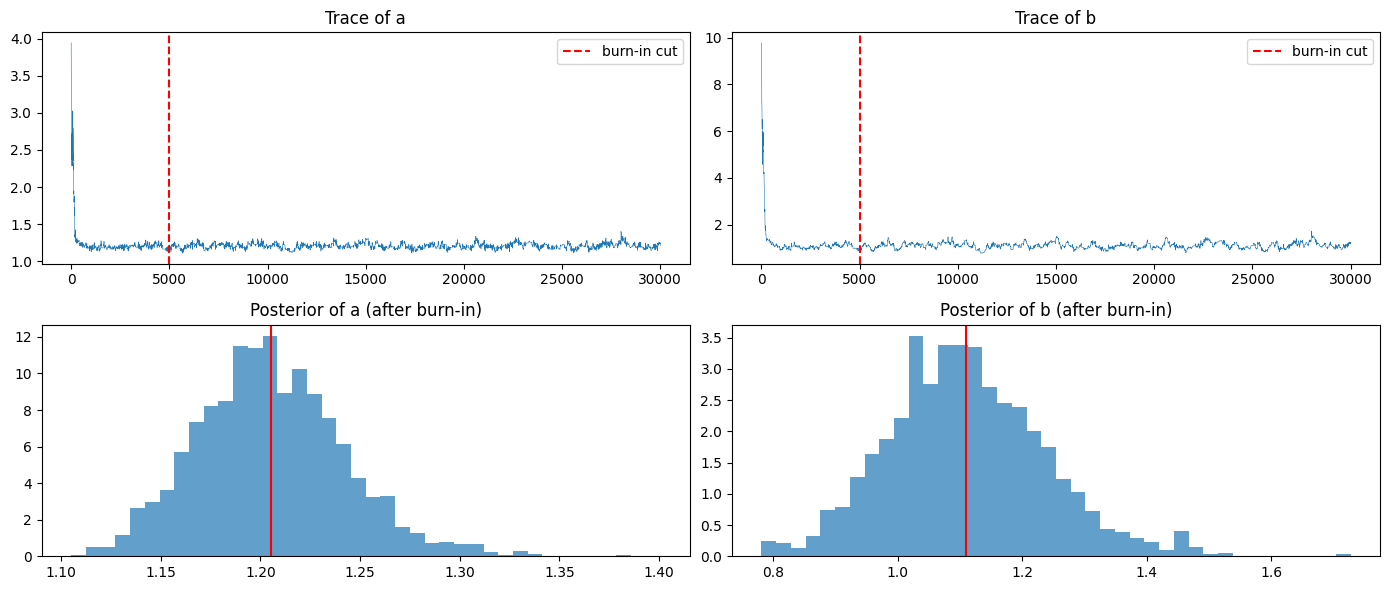

a = 1.205 ± 0.037
b = 1.110 ± 0.127
95% CI a: [1.13819211 1.28622908]
95% CI b: [0.87974574 1.38412999]
Explaination
1. The first 5000 samples (burn-in) average a = 1.24, while the rest average 1.21, so the early part was still searching and is dropped.
2. After burn-in the first and second halves of a differ by only 0.000, so the trace is stable.
3. The posterior of a is centred at 1.21 (std 0.037) and of b at 1.11 (std 0.127), each with a single bell-shaped hump.
4. The narrow 95% intervals (a: 1.14 to 1.29, b: 0.88 to 1.38) show the data pins down both parameters.


In [14]:
burn = 5000
fig, axs = plt.subplots(2, 2, figsize=(14,6))
for ax, tr, name in zip(axs[0], [a_tr, b_tr], ["a", "b"]):
    ax.plot(tr, lw=0.4)
    ax.axvline(burn, c="r", ls="--", label="burn-in cut")
    ax.set_title(f"Trace of {name}"); ax.legend()

a_post, b_post = a_tr[burn:], b_tr[burn:]
for ax, tr, name in zip(axs[1], [a_post, b_post], ["a", "b"]):
    ax.hist(tr, bins=40, density=True, alpha=0.7)
    ax.axvline(tr.mean(), c="r"); ax.set_title(f"Posterior of {name} (after burn-in)")
plt.tight_layout(); plt.show()

print(f"a = {a_post.mean():.3f} ± {a_post.std():.3f}")
print(f"b = {b_post.mean():.3f} ± {b_post.std():.3f}")
print("95% CI a:", np.percentile(a_post, [2.5, 97.5]))
print("95% CI b:", np.percentile(b_post, [2.5, 97.5]))

early_a = a_tr[:burn].mean()
late_a = a_post.mean()
half = len(a_post)//2
drift_a = abs(a_post[:half].mean() - a_post[half:].mean())

print("Explaination")
print(f"1. The first {burn} samples (burn-in) average a = {early_a:.2f}, while the rest average {late_a:.2f}, so the early part was still searching and is dropped.")
print(f"2. After burn-in the first and second halves of a differ by only {drift_a:.3f}, so the trace is stable.")
print(f"3. The posterior of a is centred at {a_post.mean():.2f} (std {a_post.std():.3f}) and of b at {b_post.mean():.2f} (std {b_post.std():.3f}), each with a single bell-shaped hump.")
print(f"4. The narrow 95% intervals (a: {np.percentile(a_post,2.5):.2f} to {np.percentile(a_post,97.5):.2f}, b: {np.percentile(b_post,2.5):.2f} to {np.percentile(b_post,97.5):.2f}) show the data pins down both parameters.")

Step 6. Prediction time of a and b

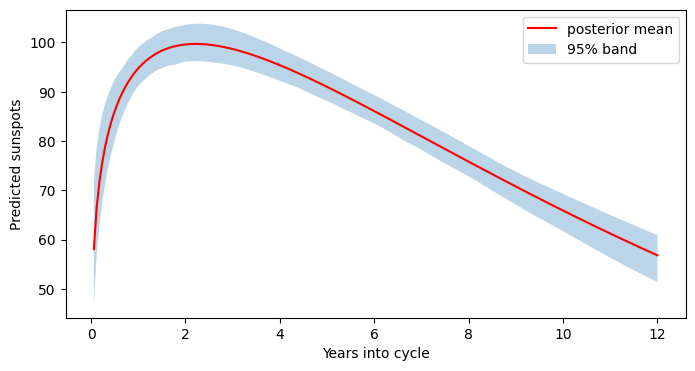

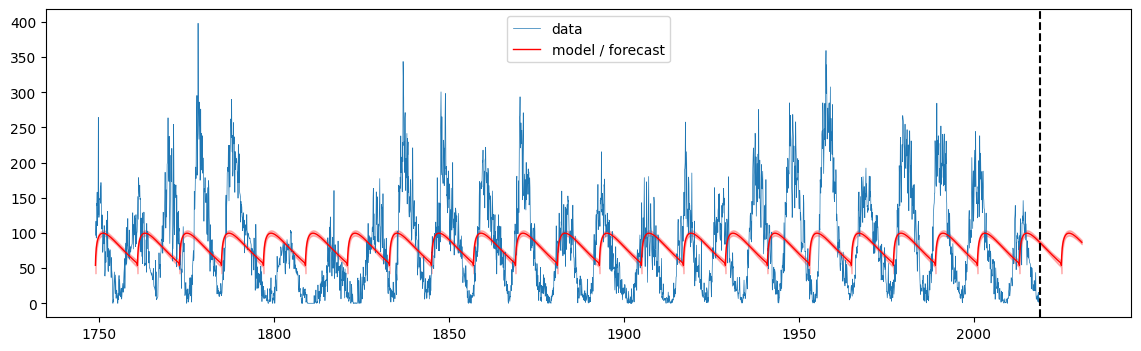

Predicted peak at phase 0.184 → 2.2 years after cycle start
Explaination
1. The average cycle peaks about 2.2 years after it starts, at roughly 100 sunspots, with a fast rise and a slow decline.
2. The 95% band at the peak runs from 96 to 104, which shows how uncertain the cycle height is.
3. The forecast beyond Nov 2018 repeats the same average cycle shape every 12 years, so it predicts a typical cycle, not exact future peaks.
4. The fit explains about 4.0% of the variance. It is limited because real cycles last about 11 years (9 to 14) while the model resets every 12 years.


In [15]:
post = chain[burn:]
idx = np.random.choice(len(post), 300, replace=False)

ug = np.linspace(0.005, 1, 200)
curves = np.array([post[i,2] * gamma_pdf(ug, post[i,0], post[i,1]) for i in idx])
plt.figure(figsize=(8,4))
plt.plot(ug*12, curves.mean(0), "r", label="posterior mean")
plt.fill_between(ug*12, *np.percentile(curves, [2.5, 97.5], axis=0), alpha=0.3, label="95% band")
plt.xlabel("Years into cycle"); plt.ylabel("Predicted sunspots"); plt.legend(); plt.show()

future = 144
m_all = np.arange(n + future)
u_all = ((m_all % CYCLE) + 0.5) / CYCLE
t_all = 1749 + m_all/12
pred = np.array([post[i,2] * gamma_pdf(u_all, post[i,0], post[i,1]) for i in idx])
plt.figure(figsize=(14,4))
plt.plot(t_years, y, lw=0.5, label="data")
plt.plot(t_all, pred.mean(0), "r", lw=1, label="model / forecast")
plt.fill_between(t_all, *np.percentile(pred, [2.5, 97.5], axis=0), color="r", alpha=0.25)
plt.axvline(2018.9, c="k", ls="--"); plt.legend(); plt.show()

pk = (post[:,0]-1)/post[:,1]
print(f"Predicted peak at phase {pk.mean():.3f} → {pk.mean()*12:.1f} years after cycle start")

mean_curve = curves.mean(0)
band = np.percentile(curves, [2.5, 97.5], axis=0)
mu_fit = post[:,2].mean() * gamma_pdf(u, post[:,0].mean(), post[:,1].mean())
r2 = 1 - np.sum((y - mu_fit)**2) / np.sum((y - y.mean())**2)

print("Explaination")
print(f"1. The average cycle peaks about {pk.mean()*12:.1f} years after it starts, at roughly {mean_curve.max():.0f} sunspots, with a fast rise and a slow decline.")
print(f"2. The 95% band at the peak runs from {band[0].max():.0f} to {band[1].max():.0f}, which shows how uncertain the cycle height is.")
print(f"3. The forecast beyond Nov 2018 repeats the same average cycle shape every 12 years, so it predicts a typical cycle, not exact future peaks.")
print(f"4. The fit explains about {r2*100:.1f}% of the variance. It is limited because real cycles last about 11 years (9 to 14) while the model resets every 12 years.")